In [1]:
import tensorflow

In [2]:
print(tensorflow.__version__)

2.21.0


In [6]:
#mounting the google drive for importing the data
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
!ls drive/MyDrive/Datasets

pneomonia.zip


In [8]:
!unzip drive/MyDrive/Datasets/pneomonia.zip

Streaming output truncated to the last 5000 lines.
  inflating: chest_xray/train/NORMAL/IM-0435-0001-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0435-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0437-0001-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0437-0001-0002.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0437-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0438-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0439-0001-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0439-0001-0002.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0439-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0440-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0441-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0442-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0444-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0445-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0446-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0447-0001.jpeg  
  inflating:

In [ ]:
#!ls /content/pneumonia/

In [ ]:
#!find /content/pneumonia -maxdepth 3 -type d

In [9]:
# import the libraries

import numpy as np

import matplotlib.pyplot as plt
import cv2
import os

In [10]:
# setting the training data dictionary
DataDir = "/content/chest_xray/train"

In [11]:
# initialize the category of classification
CATEGORIES = ["PNEUMONIA","NORMAL"]


In [12]:
!ls /content/chest_xray

chest_xray  __MACOSX  test  train  val


In [13]:
!ls /content/chest_xray/test

NORMAL	PNEUMONIA


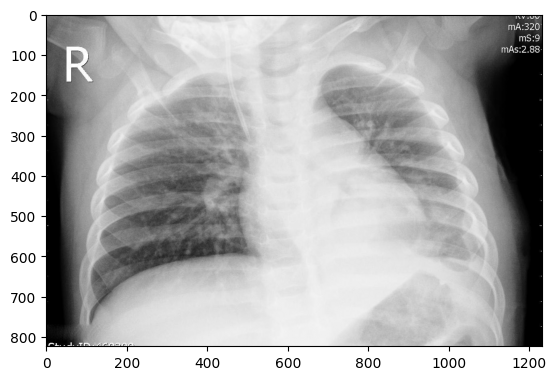

In [14]:
# convert the image into grayscale
for i in CATEGORIES:
  path=os.path.join(DataDir,i)
  for img in os.listdir(path):
    img_array=cv2.imread(os.path.join(path,img),cv2.IMREAD_GRAYSCALE)
    plt.imshow(img_array,cmap="gray")
    plt.show()
    break
  break

In [15]:
# Initialize the size of the image so that every image should be in the same directory
img_size = 100

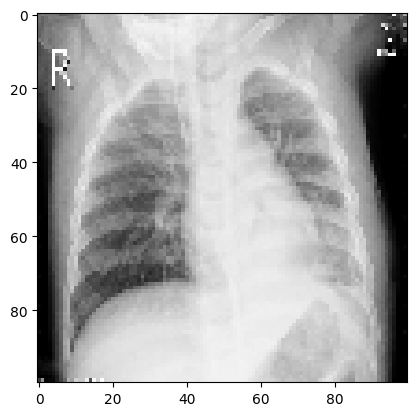

In [16]:
#image after resize and gray scele
new_array = cv2.resize(img_array,(img_size,img_size))
plt.imshow(new_array,cmap='gray')
plt.show()

In [17]:
training_data = []

In [18]:
# Create training data: each image is stored together with its label
def create_training_data():
    training_data.clear()  # Prevent duplicate data if this cell is run again

    for i in CATEGORIES:
        path = os.path.join(DataDir, i)
        class_num = CATEGORIES.index(i)

        for img in os.listdir(path):
            image_path = os.path.join(path, img)
            try:
                img_array = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

                # Skip files that OpenCV cannot read
                if img_array is None:
                    print("Could not read image:", image_path)
                    continue

                new_array = cv2.resize(img_array, (img_size, img_size))
                training_data.append([new_array, class_num])

            except Exception as e:
                print("Error processing", image_path, ":", e)


In [19]:
create_training_data()

In [20]:
print(len(training_data))

5216


In [21]:
import random
random.shuffle(training_data)
for sample in training_data[:10]:
  print(sample)

[array([[28, 26, 20, ..., 53, 45, 31],
       [23, 13, 56, ..., 59, 47, 37],
       [33, 56, 59, ..., 65, 55, 35],
       ...,
       [40, 39, 38, ..., 39, 40, 40],
       [40, 39, 38, ..., 39, 40, 40],
       [39, 39, 38, ..., 39, 39, 40]], shape=(100, 100), dtype=uint8), 0]
[array([[ 0, 15, 29, ...,  0,  0,  0],
       [ 1, 14, 30, ...,  0,  0,  0],
       [ 0, 13, 28, ...,  0,  0,  0],
       ...,
       [ 0,  0,  0, ...,  0,  0,  0],
       [ 0,  0,  0, ...,  0,  0,  0],
       [ 0,  0,  0, ...,  0,  0,  0]], shape=(100, 100), dtype=uint8), 0]
[array([[ 47,  52, 255, ...,   1,   0,   0],
       [ 42,  51, 254, ...,   0,   0,   0],
       [ 38, 252,  35, ...,   0,   0,   0],
       ...,
       [  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0]], shape=(100, 100), dtype=uint8), 0]
[array([[ 0,  0,  0, ..., 54, 48, 42],
       [ 0,  0,  0, ..., 46, 45, 36],
       [ 0,  0,  0, ..., 52, 46, 35],
       ...,
      

In [22]:
X = []
Y = []


In [23]:
# Split features and labels. Reset both arrays before filling them.
X = []
Y = []

for features, labels in training_data:
    X.append(features)
    Y.append(labels)

# Check that every image has one matching label
assert len(X) == len(Y), f"Training mismatch: {len(X)} images and {len(Y)} labels"


In [24]:
print(X[0].reshape(-1,img_size,img_size,1))

[[[[28]
   [26]
   [20]
   ...
   [53]
   [45]
   [31]]

  [[23]
   [13]
   [56]
   ...
   [59]
   [47]
   [37]]

  [[33]
   [56]
   [59]
   ...
   [65]
   [55]
   [35]]

  ...

  [[40]
   [39]
   [38]
   ...
   [39]
   [40]
   [40]]

  [[40]
   [39]
   [38]
   ...
   [39]
   [40]
   [40]]

  [[39]
   [39]
   [38]
   ...
   [39]
   [39]
   [40]]]]


In [25]:
Y=np.array(Y)


In [26]:
# reshape the feature for make it compatible with tensorflow
X=np.array(X).reshape(-1,img_size,img_size,1)

In [27]:
# As we do for trainin data similarity doing with validation data
validation_data = []
DataDir_val = "/content/chest_xray/val"

In [28]:
# Create validation data using the same preprocessing as training data
def create_validating_data():
    validation_data.clear()  # Prevent duplicate data if this cell is run again

    for i in CATEGORIES:
        path = os.path.join(DataDir_val, i)
        class_num = CATEGORIES.index(i)

        for img in os.listdir(path):
            image_path = os.path.join(path, img)
            try:
                img_array = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

                if img_array is None:
                    print("Could not read validation image:", image_path)
                    continue

                new_array = cv2.resize(img_array, (img_size, img_size))
                validation_data.append([new_array, class_num])

            except Exception as e:
                print("Error processing", image_path, ":", e)


In [29]:
create_validating_data()
print(len(validation_data))

16


In [30]:
import random
random.shuffle(validation_data)
for sample in validation_data[:10]:
    print(sample)

[array([[64, 63, 64, ..., 97, 93, 93],
       [51, 52, 50, ..., 90, 92, 90],
       [39, 41, 44, ..., 96, 86, 86],
       ...,
       [16, 51, 78, ...,  2,  2,  6],
       [28, 56, 80, ...,  2,  1,  8],
       [35, 61, 87, ...,  2, 10,  7]], shape=(100, 100), dtype=uint8), 0]
[array([[ 2, 17, 31, ..., 95, 86, 68],
       [ 6, 14, 25, ..., 94, 68, 62],
       [ 2, 10, 23, ..., 88, 73, 60],
       ...,
       [ 0,  0,  0, ...,  0,  0,  0],
       [ 0,  0,  0, ...,  0,  0,  0],
       [ 0,  0,  0, ...,  0,  0,  0]], shape=(100, 100), dtype=uint8), 1]
[array([[  0,  20,  15, ...,  10,  14,  15],
       [239,  19,  15, ...,  12,  13,  14],
       [ 21,  18,  15, ...,  11,  14,  15],
       ...,
       [ 30,  33,  31, ...,  35,  32,  32],
       [ 32,  34,  29, ...,  35,  32,  27],
       [ 44,  33,  31, ...,  37,  30,  27]], shape=(100, 100), dtype=uint8), 1]
[array([[ 0,  5, 16, ..., 79, 47, 29],
       [ 0,  3, 15, ..., 78, 47, 27],
       [ 0,  3, 16, ..., 77, 52, 25],
       ...,
      

In [31]:
X_val = []
Y_val = []


In [32]:
# Split validation features and labels
X_val = []
Y_val = []

for features, labels in validation_data:
    X_val.append(features)
    Y_val.append(labels)

assert len(X_val) == len(Y_val), (
    f"Validation mismatch: {len(X_val)} images and {len(Y_val)} labels"
)


In [33]:
Y_val=np.array(Y_val)
X_val=np.array(X_val).reshape(-1,img_size,img_size,1)

In [34]:
#Import the libraries for training the mode and adding the neural network layers

import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense, Dropout, Activation, Flatten
from keras.layers import Conv2D, MaxPooling2D
import pickle

In [35]:
X=X/255.0
X_val=X_val/255.0

In [36]:
X.shape

(5216, 100, 100, 1)

In [37]:
X_val.shape

(16, 100, 100, 1)

In [38]:
# Initialize the NN layers for training the model
model = Sequential()

In [39]:
model.add(Conv2D(64,(3,3),input_shape=X.shape[1:]))
model.add(Activation("relu"))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(.2))


model.add(Conv2D(128,(3,3)))
model.add(Activation("relu"))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(.2))

model.add(Conv2D(256,(3,3)))
model.add(Activation("relu"))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(.2))

model.add(Flatten())
model.add(Dense(64))

model.add(Dropout(.5))

model.add(Dense(1))
model.add(Activation("sigmoid"))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [40]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 98, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 98, 98, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 49, 49, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 47, 47, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 23, 23, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 21, 21, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 21, 21, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,638,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,008,193 (7.66 MB)

 Trainable params: 2,008,193 (7.66 MB)

 Non-trainable params: 0 (0.00 B)

In [41]:
model.compile(loss="binary_crossentropy",
             optimizer="adam",
             metrics=['accuracy'])

In [42]:
print("X images:", len(X))
print("Y labels:", len(Y))
print("X_val images:", len(X_val))
print("Y_val labels:", len(Y_val))

X images: 5216
Y labels: 5216
X_val images: 16
Y_val labels: 16


In [43]:
# Final check before training
print("Training images:", len(X))
print("Training labels:", len(Y))
print("Validation images:", len(X_val))
print("Validation labels:", len(Y_val))
print("X shape:", X.shape)
print("Y shape:", Y.shape)
print("X_val shape:", X_val.shape)
print("Y_val shape:", Y_val.shape)


Training images: 5216
Training labels: 5216
Validation images: 16
Validation labels: 16
X shape: (5216, 100, 100, 1)
Y shape: (5216,)
X_val shape: (16, 100, 100, 1)
Y_val shape: (16,)


In [44]:
# Make sure the data is consistent before fitting the model
assert len(X) == len(Y), "Training images and labels do not match"
assert len(X_val) == len(Y_val), "Validation images and labels do not match"
assert X.ndim == 4 and X.shape[1:] == (img_size, img_size, 1)
assert X_val.ndim == 4 and X_val.shape[1:] == (img_size, img_size, 1)

print("Dataset checks passed. Ready to train.")


Dataset checks passed. Ready to train.


In [45]:
# fitting the model with 10 epochs and using validation data we have created

model.fit(X,Y,batch_size=5,epochs=10,validation_data=(X_val,Y_val))

Epoch 1/10
1044/1044 ━━━━━━━━━━━━━━━━━━━━ 32s 18ms/step - accuracy: 0.8831 - loss: 0.2903 - val_accuracy: 0.8125 - val_loss: 0.4052
Epoch 2/10
1044/1044 ━━━━━━━━━━━━━━━━━━━━ 17s 6ms/step - accuracy: 0.9467 - loss: 0.1452 - val_accuracy: 0.9375 - val_loss: 0.1450
Epoch 3/10
1044/1044 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9559 - loss: 0.1171 - val_accuracy: 0.8750 - val_loss: 0.1910
Epoch 4/10
1044/1044 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.9641 - loss: 0.1014 - val_accuracy: 1.0000 - val_loss: 0.0783
Epoch 5/10
1044/1044 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9672 - loss: 0.0930 - val_accuracy: 1.0000 - val_loss: 0.0704
Epoch 6/10
1044/1044 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.9693 - loss: 0.0817 - val_accuracy: 0.8125 - val_loss: 0.3401
Epoch 7/10
1044/1044 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9672 - loss: 0.0897 - val_accuracy: 1.0000 - val_loss: 0.0697
Epoch 8/10
1044/1044 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9753 - loss: 0.0702

In [47]:
# save the model
model.save(r"model_10.keras")

In [48]:
#import the libraries for testing the model

import cv2
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from keras.models import load_model

CATEGORIES = ['NORMAL','PNEUMONIA']

In [49]:
#Function for prepare the image for predict the class

def prepare(image):
  image_size =100
  #image_array = cv2.imread(image,cv2.IMREAD_GRAYSCALE)
  img = tf.keras.preprocessing.image.load_img(image,color_mode='grayscale',target_size=(image_size,image_size))
  new_array = tf.keras.preprocessing.image.img_to_array(img)
  return new_array.reshape(-1,img_size,img_size,1)


In [52]:
!ls /content/chest_xray/test/NORMAL/

IM-0001-0001.jpeg	   NORMAL2-IM-0173-0001-0001.jpeg
IM-0003-0001.jpeg	   NORMAL2-IM-0173-0001-0002.jpeg
IM-0005-0001.jpeg	   NORMAL2-IM-0195-0001.jpeg
IM-0006-0001.jpeg	   NORMAL2-IM-0196-0001.jpeg
IM-0007-0001.jpeg	   NORMAL2-IM-0198-0001.jpeg
IM-0009-0001.jpeg	   NORMAL2-IM-0199-0001.jpeg
IM-0010-0001.jpeg	   NORMAL2-IM-0201-0001.jpeg
IM-0011-0001-0001.jpeg	   NORMAL2-IM-0206-0001.jpeg
IM-0011-0001-0002.jpeg	   NORMAL2-IM-0207-0001.jpeg
IM-0011-0001.jpeg	   NORMAL2-IM-0210-0001.jpeg
IM-0013-0001.jpeg	   NORMAL2-IM-0213-0001.jpeg
IM-0015-0001.jpeg	   NORMAL2-IM-0217-0001.jpeg
IM-0016-0001.jpeg	   NORMAL2-IM-0219-0001.jpeg
IM-0017-0001.jpeg	   NORMAL2-IM-0221-0001.jpeg
IM-0019-0001.jpeg	   NORMAL2-IM-0222-0001.jpeg
IM-0021-0001.jpeg	   NORMAL2-IM-0229-0001.jpeg
IM-0022-0001.jpeg	   NORMAL2-IM-0232-0001.jpeg
IM-0023-0001.jpeg	   NORMAL2-IM-0233-0001.jpeg
IM-0025-0001.jpeg	   NORMAL2-IM-0237-0001.jpeg
IM-0027-0001.jpeg	   NORMAL2-IM-0238-0001.jpeg
IM-0028-0001.jpeg	   NORMAL2-IM-0241-000

In [50]:
model = tf.keras.models.load_model(r"model_10.keras")

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 12 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [59]:
image = "/content/chest_xray/test/NORMAL/IM-0085-0001.jpeg"



In [60]:
prediction = model.predict([prepare(image)/255.0])
print(prediction)

print(round(prediction[0][0]))
print(CATEGORIES[int(round(prediction[0][0]))])


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=('Tensor(shape=(1, 100, 100, 1))',)
  warnings.warn(msg)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 484ms/step
[[0.00016165]]
0
NORMAL


In [68]:

import os
import cv2
import numpy as np

test_dir = "/content/chest_xray/test"

test_data = []
CATEGORIES = ["PNEUMONIA", "NORMAL"]

for category in CATEGORIES:
    path = os.path.join(test_dir, category)
    class_num = CATEGORIES.index(category)

    for img in os.listdir(path):
        image_path = os.path.join(path, img)

        try:
            img_array = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

            if img_array is None:
                print("Could not read:", image_path)
                continue

            new_array = cv2.resize(img_array, (100, 100))
            test_data.append([new_array, class_num])

        except Exception as e:
            print("Error:", image_path, e)

print("Total test images:", len(test_data))


Total test images: 624


In [69]:

X_test = []
Y_test = []

for features, labels in test_data:
    X_test.append(features)
    Y_test.append(labels)

X_test = np.array(X_test).reshape(-1, 100, 100, 1)
Y_test = np.array(Y_test)

print("X_test shape:", X_test.shape)
print("Y_test shape:", Y_test.shape)

assert len(X_test) == len(Y_test), "Test data mismatch!"


X_test shape: (624, 100, 100, 1)
Y_test shape: (624,)


In [70]:

X_test = X_test / 255.0


In [71]:

test_loss, test_accuracy = model.evaluate(X_test, Y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7292 - loss: 1.2661
Test Loss: 1.2661056518554688
Test Accuracy: 0.7291666865348816


20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
Accuracy: 0.7291666666666666

Classification Report:
              precision    recall  f1-score   support

   PNEUMONIA       0.70      1.00      0.82       390
      NORMAL       1.00      0.28      0.43       234

    accuracy                           0.73       624
   macro avg       0.85      0.64      0.63       624
weighted avg       0.81      0.73      0.68       624



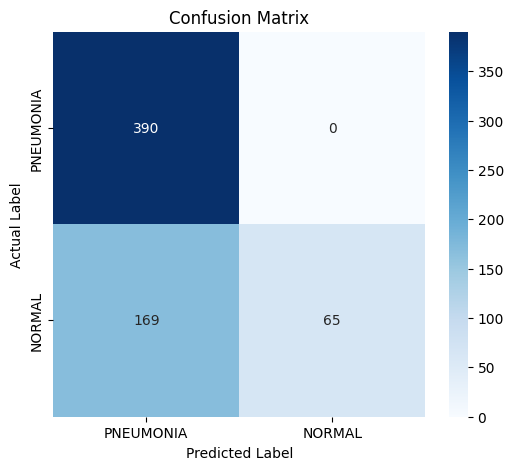

In [72]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)
import matplotlib.pyplot as plt
import seaborn as sns

# Get predictions
predictions = model.predict(X_test)

# Convert probabilities into class labels
Y_pred = (predictions.ravel() >= 0.5).astype(int)

# Calculate accuracy
print("Accuracy:", accuracy_score(Y_test, Y_pred))

# Classification report
print("\nClassification Report:")
print(classification_report(
    Y_test,
    Y_pred,
    target_names=CATEGORIES
))

# Confusion matrix
cm = confusion_matrix(Y_test, Y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=CATEGORIES,
    yticklabels=CATEGORIES
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()


In [73]:

# Check actual test labels
print("Actual label distribution:")
print("NORMAL:", np.sum(Y_test == 0))
print("PNEUMONIA:", np.sum(Y_test == 1))

# Check predicted label distribution
print("\nPredicted label distribution:")
print("NORMAL:", np.sum(Y_pred == 0))
print("PNEUMONIA:", np.sum(Y_pred == 1))

# Check prediction probabilities
print("\nPrediction probabilities:")
print("Minimum:", predictions.min())
print("Maximum:", predictions.max())
print("Mean:", predictions.mean())

# Display confusion matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(Y_test, Y_pred)
print("\nConfusion Matrix:")
print(cm)


Actual label distribution:
NORMAL: 390
PNEUMONIA: 234

Predicted label distribution:
NORMAL: 559
PNEUMONIA: 65

Prediction probabilities:
Minimum: 5.6562116e-10
Maximum: 0.999995
Mean: 0.1121855

Confusion Matrix:
[[390   0]
 [169  65]]


In [74]:
model.summary()
print("\nFinal layer:", model.layers[-1].get_config())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 98, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 98, 98, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 49, 49, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 47, 47, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 23, 23, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 21, 21, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 21, 21, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 10, 10, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,638,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,016,388 (15.32 MB)

 Trainable params: 2,008,193 (7.66 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,008,195 (7.66 MB)


Final layer: {'name': 'activation_3', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'activation': 'sigmoid'}


Saving normal_pneomonia_1.jfif to normal_pneomonia_1.jfif


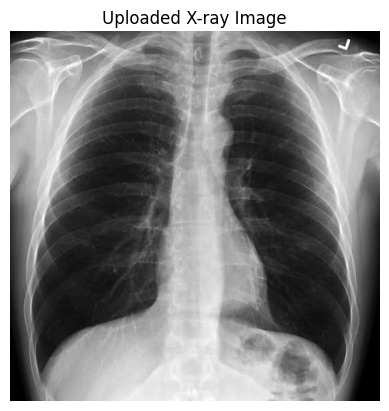

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
Model Prediction: NORMAL
Prediction Score: 0.8063708543777466


In [77]:
from google.colab import files
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Upload an X-ray image
uploaded = files.upload()

# Get uploaded image path
image_path = list(uploaded.keys())[0]

# Display the image
img = Image.open(image_path)
plt.imshow(img, cmap="gray")
plt.title("Uploaded X-ray Image")
plt.axis("off")
plt.show()

# Prepare image for model
test_image = prepare(image_path) / 255.0

# Make prediction
prediction = model.predict(test_image)

# Get predicted class
predicted_class = round(float(prediction[0][0]))

# Class names (same order used during training)
CATEGORIES = ["PNEUMONIA", "NORMAL"]

print("Model Prediction:", CATEGORIES[predicted_class])
print("Prediction Score:", float(prediction[0][0]))